**此文件已修复三处 bug(2026-09-29）：**
1. `knn_impute` 补上了缺失的 `scaler.inverse_transform()`
2. MCAR 的 Mean/Median/KNN 结果原本是硬编码数字，改成用 `evaluate_imputation` 现算
3. **新增**：MNAR 的 Mean 结果（`mnar_mean_results`）算出来后从没 `extend` 进最终的 `results` 列表，导致最后只有 33 行（少了 MNAR/Mean 的 3 行：0.1/0.3/0.5）。已补上 `results.extend(mnar_mean_results)`。

**你需要做的事：Kernel → Restart & Run All**，跑完后 `results_df` 应该是 36 行，`imputation_results.csv` 也会随之更新。


In [3]:
import pandas as pd
import numpy as np

In [4]:
path = "/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/processed dataset/final_df_(distance)_v2.parquet"

In [5]:
df = pd.read_parquet(path)

In [6]:
df.shape

(99418, 28)

In [7]:
final_features = [
    "total_price",
    "total_freight_value",
    "total_product_weight_g",
    "average_product_length_cm",
    "average_product_height_cm",
    "item_count",
    "max_payment_installments",
    "average_distance_km"
]

model_df = df.dropna(
    subset=final_features + ["is_delayed"]
).copy()

print(model_df.shape)

(95959, 28)


In [8]:
model_df[final_features + ["delivery_delay_days"]].corr()["delivery_delay_days"].sort_values()

average_distance_km         -0.075840
total_freight_value         -0.049377
item_count                  -0.031624
max_payment_installments    -0.031055
total_price                 -0.013045
average_product_height_cm   -0.002287
total_product_weight_g       0.002342
average_product_length_cm    0.009616
delivery_delay_days          1.000000
Name: delivery_delay_days, dtype: float64

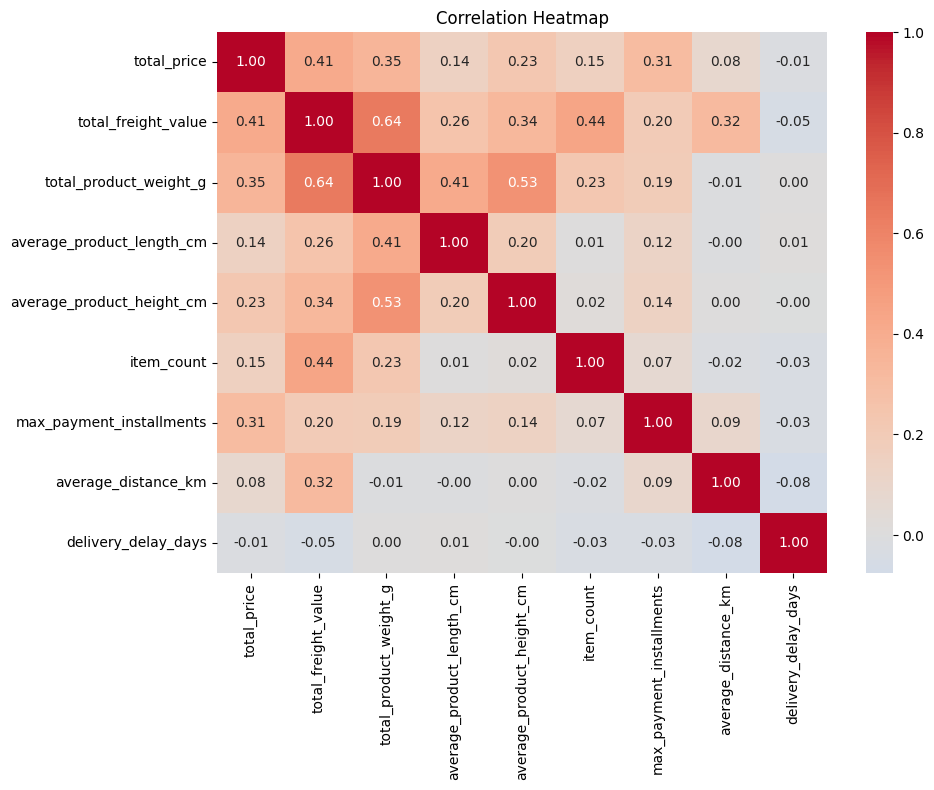

In [9]:
import seaborn as sns

import matplotlib.pyplot as plt

# Use only numeric modelling columns; exclude IDs, text, dates, and timedeltas
corr_columns = final_features + ["delivery_delay_days"]
corr = model_df[corr_columns].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [10]:
df.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'item_count', 'total_price', 'total_freight_value', 'n_unique_products',
       'n_unique_sellers', 'total_product_weight_g',
       'average_product_length_cm', 'average_product_height_cm',
       'average_product_width_cm', 'n_unique_categories',
       'n_unique_seller_city', 'n_unique_seller_state', 'total_payment_value',
       'max_payment_installments', 'n_unique_payment_types',
       'average_distance_km', 'customer_city', 'customer_state',
       'delivery_delay_days', 'is_delayed'],
      dtype='object')

In [11]:
corr_matrix = df.corr(numeric_only=True).round(3)

corr_matrix["delivery_delay_days"].sort_values(ascending=False)

delivery_delay_days          1.000
is_delayed                   0.595
average_product_length_cm    0.010
total_product_weight_g       0.003
average_product_width_cm     0.000
average_product_height_cm   -0.002
n_unique_payment_types      -0.009
total_price                 -0.014
total_payment_value         -0.018
n_unique_categories         -0.028
max_payment_installments    -0.031
item_count                  -0.032
n_unique_products           -0.047
total_freight_value         -0.049
n_unique_seller_state       -0.050
n_unique_seller_city        -0.057
n_unique_sellers            -0.058
average_distance_km         -0.076
Name: delivery_delay_days, dtype: float64

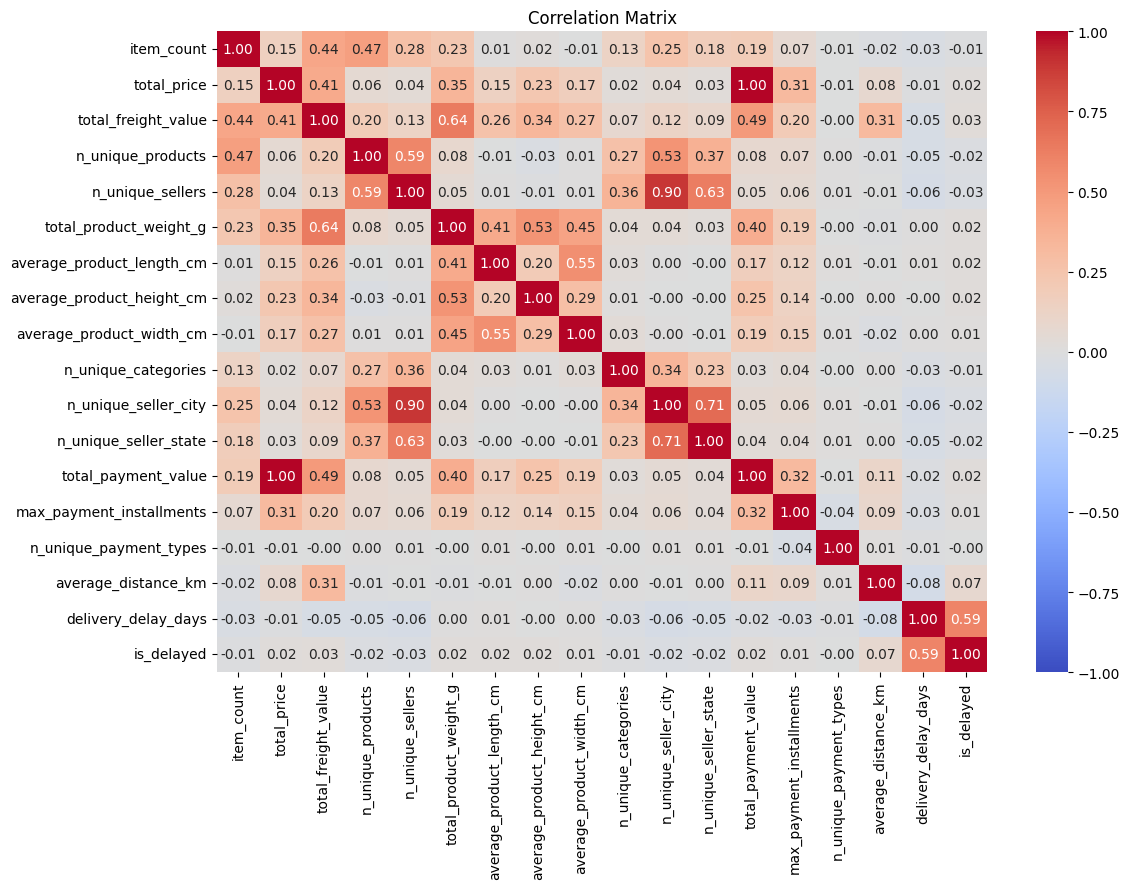

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [13]:
corr_matrix.corr().round(5)

,item_count,total_price,total_freight_value,n_unique_products,n_unique_sellers,total_product_weight_g,average_product_length_cm,average_product_height_cm,average_product_width_cm,n_unique_categories,n_unique_seller_city,n_unique_seller_state,total_payment_value,max_payment_installments,n_unique_payment_types,average_distance_km,delivery_delay_days,is_delayed
item_count,1.00000,0.06719,0.41132,0.64845,0.39543,0.11210,-0.22368,-0.15122,-0.23729,0.17854,0.36055,0.28358,0.09762,-0.06306,-0.18822,-0.14146,-0.31301,-0.31790
total_price,0.06719,1.00000,0.57067,-0.23331,-0.30340,0.48851,0.16690,0.35549,0.20587,-0.27651,-0.30533,-0.29612,0.99772,0.46570,-0.20198,0.05340,-0.23336,-0.21619
total_freight_value,0.41132,0.57067,1.00000,-0.06778,-0.22369,0.78675,0.31750,0.49920,0.34132,-0.24043,-0.23751,-0.25230,0.62484,0.24616,-0.27017,0.27526,-0.39284,-0.32886
n_unique_products,0.64845,-0.23331,-0.06778,1.00000,0.83355,-0.27063,-0.36790,-0.38790,-0.37456,0.48608,0.79643,0.68760,-0.22719,-0.17457,-0.16002,-0.21730,-0.33640,-0.34488
n_unique_sellers,0.39543,-0.30340,-0.22369,0.83355,1.00000,-0.36099,-0.37127,-0.39520,-0.38460,0.57858,0.99147,0.90105,-0.30669,-0.21497,-0.14331,-0.22412,-0.33291,-0.33859
total_product_weight_g,0.11210,0.48851,0.78675,-0.27063,-0.36099,1.00000,0.61077,0.76700,0.66475,-0.30076,-0.36736,-0.36637,0.52927,0.24226,-0.22520,-0.10681,-0.24784,-0.25943
average_product_length_cm,-0.22368,0.16690,0.31750,-0.36790,-0.37127,0.61077,1.00000,0.40282,0.82610,-0.26133,-0.37156,-0.35709,0.18470,0.12815,-0.13947,-0.13900,-0.14189,-0.16896
average_product_height_cm,-0.15122,0.35549,0.49920,-0.38790,-0.39520,0.76700,0.40282,1.00000,0.51402,-0.29847,-0.39002,-0.37054,0.37908,0.19135,-0.16157,-0.09218,-0.16718,-0.17754
average_product_width_cm,-0.23729,0.20587,0.34132,-0.37456,-0.38460,0.66475,0.82610,0.51402,1.00000,-0.26939,-0.38532,-0.37216,0.22383,0.16628,-0.14733,-0.16219,-0.16352,-0.19279
n_unique_categories,0.17854,-0.27651,-0.24043,0.48608,0.57858,-0.30076,-0.26133,-0.29847,-0.26939,1.00000,0.56517,0.47000,-0.28284,-0.19525,-0.13601,-0.18509,-0.25846,-0.27497


In [14]:
model_df[final_features].corr().round(3)

,total_price,total_freight_value,total_product_weight_g,average_product_length_cm,average_product_height_cm,item_count,max_payment_installments,average_distance_km
total_price,1.000,0.411,0.351,0.145,0.228,0.154,0.315,0.081
total_freight_value,0.411,1.000,0.641,0.258,0.335,0.439,0.199,0.316
total_product_weight_g,0.351,0.641,1.000,0.412,0.531,0.230,0.190,-0.010
average_product_length_cm,0.145,0.258,0.412,1.000,0.197,0.008,0.124,-0.005
average_product_height_cm,0.228,0.335,0.531,0.197,1.000,0.018,0.137,0.000
item_count,0.154,0.439,0.230,0.008,0.018,1.000,0.068,-0.016
max_payment_installments,0.315,0.199,0.190,0.124,0.137,0.068,1.000,0.091
average_distance_km,0.081,0.316,-0.010,-0.005,0.000,-0.016,0.091,1.000


# Missing injection

In [15]:
final_features = [
    "total_price",
    "total_freight_value",
    "total_product_weight_g",
    "average_product_length_cm",
    "average_product_height_cm",
    "item_count",
    "max_payment_installments",
    "average_distance_km"
]

In [16]:
experiment_columns = [
    "order_id",
    *final_features,
    "is_delayed"
]

In [17]:
model_df = df[experiment_columns].dropna().copy()

print(model_df.shape)
print(model_df.columns)

(95959, 10)
Index(['order_id', 'total_price', 'total_freight_value',
       'total_product_weight_g', 'average_product_length_cm',
       'average_product_height_cm', 'item_count', 'max_payment_installments',
       'average_distance_km', 'is_delayed'],
      dtype='object')


In [18]:
print(model_df.isna().sum())

order_id                     0
total_price                  0
total_freight_value          0
total_product_weight_g       0
average_product_length_cm    0
average_product_height_cm    0
item_count                   0
max_payment_installments     0
average_distance_km          0
is_delayed                   0
dtype: int64


In [19]:
target = "total_freight_value"

print("Target:", target)
print("Mean:", model_df[target].mean())
print("Missing:", model_df[target].isna().sum())

Target: total_freight_value
Mean: 22.777071249179336
Missing: 0


## MCAR injection

In [20]:
def inject_mcar(df, target, missing_rate, random_seed = 42):
    df_injected = df.copy()

    rng = np.random.default_rng(random_seed)

    n_missing = int(len(df_injected) * missing_rate)

    missing_indices = rng.choice(
        df_injected.index,
        size = n_missing,
        replace = False
    )

    df_injected.loc[missing_indices, target] = np.nan

    return df_injected

In [21]:
mcar_10 = inject_mcar(
    model_df,
    target = 'total_freight_value',
    missing_rate=0.1
)

mcar_30 = inject_mcar(
    model_df,
    target = 'total_freight_value',
    missing_rate=0.3
)

mcar_50 = inject_mcar(
    model_df,
    target = 'total_freight_value',
    missing_rate = 0.5
)

In [22]:
for name, data in {
    'MCAR 10%':mcar_10,
    'MCAR 30%':mcar_30,
    'MCAR 50%':mcar_50
}.items():
    print(
        name,
        '| missing: ',
        data['total_freight_value'].isna().sum(),
        '| rate: ',
        data['total_freight_value'].isna().mean()
    )

MCAR 10% | missing:  9595 | rate:  0.09999062099438302
MCAR 30% | missing:  28787 | rate:  0.2999927052178535
MCAR 50% | missing:  47979 | rate:  0.4999947894413239


In [23]:
mcar_10.to_parquet("/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mcar_10.parquet", index=False)
mcar_30.to_parquet("/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mcar_30.parquet", index=False)
mcar_50.to_parquet("/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mcar_50.parquet", index=False)

In [24]:
mcar_10_mask = mcar_10["total_freight_value"].isna()
mcar_30_mask = mcar_30["total_freight_value"].isna()
mcar_50_mask = mcar_50["total_freight_value"].isna()

## MAR injection

For the simulated MAR mechanism, missingness in total_freight_value was generated as a function of the observed total_product_weight_g, an auxiliary variable strongly associated with freight value in the dataset.

In [25]:
#total_product_weight_g 越高 → 被选为 missing 的概率越高
def inject_mar(df,target, auxiliary, missing_rate, random_seed=42):
    df_injected = df.copy()

    rng = np.random.default_rng(random_seed)

    #high auxiliary vlaues --》 higher probability of being selected 
    weights = df_injected[auxiliary].rank(pct = True).to_numpy()
    weights = weights +0.01
    weights = weights/weights.sum()

    n_missing = int(len(df_injected)* missing_rate)

    missing_indices = rng.choice(
        df_injected.index,
        size = n_missing,
        replace = False,
        p = weights
    )

    df_injected.loc[missing_indices, target]=np.nan

    return df_injected

In [26]:
mar_10 = inject_mar(
    model_df,
    target="total_freight_value",
    auxiliary="total_product_weight_g",
    missing_rate=0.10,
    random_seed=42
)

In [27]:
mar_10.describe()

,total_price,total_freight_value,total_product_weight_g,average_product_length_cm,average_product_height_cm,item_count,max_payment_installments,average_distance_km
count,95959.000000,86364.000000,95959.000000,95959.000000,95959.000000,95959.000000,95959.000000,95959.000000
mean,137.070542,22.209299,2384.540054,30.077289,16.462973,1.142071,2.926583,600.454988
std,209.235363,20.782705,4767.849763,16.035760,13.250150,0.538868,2.711746,592.104385
min,0.850000,0.000000,0.000000,7.000000,2.000000,1.000000,0.000000,0.000000
25%,45.900000,13.710000,300.000000,18.000000,8.000000,1.000000,1.000000,187.751161
50%,86.000000,16.950000,750.000000,25.000000,13.000000,1.000000,2.000000,433.839063
75%,149.900000,23.490000,2050.000000,38.000000,20.000000,1.000000,4.000000,797.601773
max,13440.000000,1794.960000,184400.000000,105.000000,105.000000,21.000000,24.000000,3399.190906


In [28]:
mar_mask = mar_10["total_freight_value"].isna()

print("Missing group weight mean:",
      model_df.loc[mar_mask, "total_product_weight_g"].mean())

print("Observed group weight mean:",
      model_df.loc[~mar_mask, "total_product_weight_g"].mean())

Missing group weight mean: 4025.5942678478373
Observed group weight mean: 2202.2196980223243


In [29]:
mar_30 = inject_mar(
    model_df,
    target="total_freight_value",
    auxiliary="total_product_weight_g",
    missing_rate=0.30,
    random_seed=42
)

mar_50 = inject_mar(
    model_df,
    target="total_freight_value",
    auxiliary="total_product_weight_g",
    missing_rate=0.50,
    random_seed=42
)

In [30]:
print("MAR 30%:", mar_30["total_freight_value"].isna().mean())
print("MAR 50%:", mar_50["total_freight_value"].isna().mean())

MAR 30%: 0.2999927052178535
MAR 50%: 0.4999947894413239


In [31]:
mar_30_mask = mar_30["total_freight_value"].isna()
mar_50_mask = mar_50["total_freight_value"].isna()

print("MAR 30%")
print("Missing group:", model_df.loc[mar_30_mask, "total_product_weight_g"].mean())
print("Observed group:", model_df.loc[~mar_30_mask, "total_product_weight_g"].mean())

print("\nMAR 50%")
print("Missing group:", model_df.loc[mar_50_mask, "total_product_weight_g"].mean())
print("Observed group:", model_df.loc[~mar_50_mask, "total_product_weight_g"].mean())

MAR 30%
Missing group: 3689.241393684649
Observed group: 1825.401759661764

MAR 50%
Missing group: 3432.4371287438253
Observed group: 1336.6648186744476


MAR validation by missingness rate

Mean product weight for records with missing versus observed total_freight_value.

In [32]:
# Save MAR
mar_10.to_parquet("/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mar_10.parquet", index=False)
mar_30.to_parquet("/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mar_30.parquet", index=False)
mar_50.to_parquet("/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mar_50.parquet", index=False)

In [33]:
import os

for file in [
    "/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mcar_10.parquet",
    "/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mcar_30.parquet",
    "/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mcar_50.parquet",
    "/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mar_10.parquet",
    "/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mar_30.parquet",
    "/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mar_50.parquet"
]:
    print(file, os.path.exists(file))

/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mcar_10.parquet True
/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mcar_30.parquet True
/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mcar_50.parquet True
/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mar_10.parquet True
/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mar_30.parquet True
/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mar_50.parquet True


## MNAR injection

In [34]:
def inject_mnar(df, target, missing_rate, random_seed=42):
    df_injected = df.copy()

    rng = np.random.default_rng(random_seed)

    weights = df_injected[target].rank(pct=True).to_numpy()
    weights = weights + 0.01
    weights = weights / weights.sum()

    n_missing = int(len(df_injected) * missing_rate)

    missing_indices = rng.choice(
        df_injected.index,
        size=n_missing,
        replace=False,
        p=weights
    )

    df_injected.loc[missing_indices, target] = np.nan

    return df_injected

In [35]:
mnar_10 = inject_mnar(
    model_df,
    target="total_freight_value",
    missing_rate=0.10,
    random_seed=42
)

In [36]:
mnar_mask = mnar_10["total_freight_value"].isna()

print("Missing group original mean:",
      model_df.loc[mnar_mask, "total_freight_value"].mean())

print("Observed group mean:",
      model_df.loc[~mnar_mask, "total_freight_value"].mean())

Missing group original mean: 30.5333705054716
Observed group mean: 21.91535003010514


In [37]:
mnar_30 = inject_mnar(
    model_df,
    target="total_freight_value",
    missing_rate=0.30,
    random_seed=42
)

mnar_50 = inject_mnar(
    model_df,
    target="total_freight_value",
    missing_rate=0.50,
    random_seed=42
)

In [38]:
mnar_30_mask = mnar_30["total_freight_value"].isna()
mnar_50_mask = mnar_50["total_freight_value"].isna()

print("MNAR 30%")
print("Missing group:",
      model_df.loc[mnar_30_mask, "total_freight_value"].mean())
print("Observed group:",
      model_df.loc[~mnar_30_mask, "total_freight_value"].mean())

print("\nMNAR 50%")
print("Missing group:",
      model_df.loc[mnar_50_mask, "total_freight_value"].mean())
print("Observed group:",
      model_df.loc[~mnar_50_mask, "total_freight_value"].mean())

MNAR 30%
Missing group: 29.26157258484733
Observed group: 19.9980957839576

MNAR 50%
Missing group: 28.00438087496613
Observed group: 17.54987057107128


In [39]:
mnar_10.to_parquet("/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mnar_10.parquet", index=False)
mnar_30.to_parquet("/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mnar_30.parquet", index=False)
mnar_50.to_parquet("/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/exp_data/mnar_50.parquet", index=False)

# Imputation

## Imputation for MCAR

In [40]:
# Save missing masks for later evaluation
mcar_10_mask = mcar_10["total_freight_value"].isna()
mcar_30_mask = mcar_30["total_freight_value"].isna()
mcar_50_mask = mcar_50["total_freight_value"].isna()

mar_10_mask = mar_10["total_freight_value"].isna()
mar_30_mask = mar_30["total_freight_value"].isna()
mar_50_mask = mar_50["total_freight_value"].isna()

mnar_10_mask = mnar_10["total_freight_value"].isna()
mnar_30_mask = mnar_30["total_freight_value"].isna()
mnar_50_mask = mnar_50["total_freight_value"].isna()

In [41]:
mcar_10_mask.sum()

np.int64(9595)

### Mean Imputation

In [42]:
from sklearn.impute import SimpleImputer

# Copy the injected dataset
mcar_10_mean = mcar_10.copy()

# Create imputer
mean_imputer = SimpleImputer(strategy="mean")

# Impute total_freight_value
mcar_10_mean[["total_freight_value"]] = mean_imputer.fit_transform(
    mcar_10_mean[["total_freight_value"]]
)

In [43]:
mcar_10_mean["total_freight_value"].isna().sum()

np.int64(0)

In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

original_values = model_df.loc[
    mcar_10_mask, "total_freight_value"
]

imputed_values = mcar_10_mean.loc[
    mcar_10_mask, "total_freight_value"
]

mae = mean_absolute_error(original_values, imputed_values)

rmse = np.sqrt(
    mean_squared_error(original_values, imputed_values)
)

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 11.016221856138358
RMSE: 19.083058544866578


#### mae,rmse function

In [45]:
def evaluate_imputation(original_df, imputed_df, mask, target):
    original_values = original_df.loc[mask, target]
    imputed_values = imputed_df.loc[mask, target]

    mae = mean_absolute_error(original_values, imputed_values)
    rmse = np.sqrt(
        mean_squared_error(original_values, imputed_values)
    )

    return mae, rmse

In [46]:
# MCAR 30% - Mean
mcar_30_mean = mcar_30.copy()

mcar_30_mean[["total_freight_value"]] = mean_imputer.fit_transform(
    mcar_30_mean[["total_freight_value"]]
)

mcar_30_mean_mae, mcar_30_mean_rmse = evaluate_imputation(
    model_df,
    mcar_30_mean,
    mcar_30_mask,
    "total_freight_value"
)

print("MCAR 30% Mean")
print("MAE:", mcar_30_mean_mae)
print("RMSE:", mcar_30_mean_rmse)

MCAR 30% Mean
MAE: 11.242037468525485
RMSE: 20.34717593078825


In [47]:
mcar_50_mean = mcar_50.copy()

mcar_50_mean[["total_freight_value"]] = mean_imputer.fit_transform(
    mcar_50_mean[["total_freight_value"]]
)

mcar_50_mean_mae, mcar_50_mean_rmse = evaluate_imputation(
    model_df,
    mcar_50_mean,
    mcar_50_mask,
    "total_freight_value"
)

print("MCAR 50% Mean")
print("MAE:", mcar_50_mean_mae)
print("RMSE:", mcar_50_mean_rmse)

MCAR 50% Mean
MAE: 11.360865554956
RMSE: 21.056505725223477


### Median imputation

In [48]:
from sklearn.impute import SimpleImputer

median_imputer = SimpleImputer(strategy="median")

mcar_10_median = mcar_10.copy()

mcar_10_median[["total_freight_value"]] = median_imputer.fit_transform(
    mcar_10_median[["total_freight_value"]]
)

mcar_10_median_mae, mcar_10_median_rmse = evaluate_imputation(
    model_df,
    mcar_10_median,
    mcar_10_mask,
    "total_freight_value"
)

print("MCAR 10% Median")
print("MAE:", mcar_10_median_mae)
print("RMSE:", mcar_10_median_rmse)

MCAR 10% Median
MAE: 9.365610213652944
RMSE: 19.723626845369566


In [49]:
mcar_30_median = mcar_30.copy()

mcar_30_median[["total_freight_value"]] = median_imputer.fit_transform(
    mcar_30_median[["total_freight_value"]]
)

mcar_30_median_mae, mcar_30_median_rmse = evaluate_imputation(
    model_df,
    mcar_30_median,
    mcar_30_mask,
    "total_freight_value"
)

print("MCAR 30% Median")
print("MAE:", mcar_30_median_mae)
print("RMSE:", mcar_30_median_rmse)

MCAR 30% Median
MAE: 9.659791572584847
RMSE: 21.049396742264516


In [50]:
mcar_50_median = mcar_50.copy()

mcar_50_median[["total_freight_value"]] = median_imputer.fit_transform(
    mcar_50_median[["total_freight_value"]]
)

mcar_50_median_mae, mcar_50_median_rmse = evaluate_imputation(
    model_df,
    mcar_50_median,
    mcar_50_mask,
    "total_freight_value"
)

print("MCAR 50% Median")
print("MAE:", mcar_50_median_mae)
print("RMSE:", mcar_50_median_rmse)

MCAR 50% Median
MAE: 9.74654848996436
RMSE: 21.75186919074385


### KNN imputation

In [51]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

knn_features = [
    "total_price",
    "total_freight_value",
    "total_product_weight_g",
    "average_product_length_cm",
    "average_product_height_cm",
    "item_count",
    "max_payment_installments",
    "average_distance_km"
]

In [52]:
scaler = StandardScaler()

X_mcar_10 = mcar_10[knn_features].copy()

X_scaled = scaler.fit_transform(X_mcar_10)

In [53]:
knn_imputer = KNNImputer(
    n_neighbors=5,
    weights="uniform"
)

X_imputed_scaled = knn_imputer.fit_transform(X_scaled)

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: in

In [54]:
X_imputed_scaled = pd.DataFrame(
    X_imputed_scaled,
    columns=knn_features,
    index=mcar_10.index
)

In [55]:
mcar_10_knn = mcar_10.copy()

mcar_10_knn["total_freight_value"] = (
    X_imputed_scaled["total_freight_value"]
)

In [56]:
mcar_10_knn["total_freight_value"].isna().sum()

np.int64(0)

In [57]:
original_values = model_df.loc[
    mcar_10_mask, "total_freight_value"
]

imputed_values = mcar_10_knn.loc[
    mcar_10_mask, "total_freight_value"
]

mcar_10_knn_mae = mean_absolute_error(
    original_values,
    imputed_values
)

mcar_10_knn_rmse = np.sqrt(
    mean_squared_error(
        original_values,
        imputed_values
    )
)

print("MCAR 10% KNN")
print("MAE:", mcar_10_knn_mae)
print("RMSE:", mcar_10_knn_rmse)

MCAR 10% KNN
MAE: 22.258251628944418
RMSE: 28.928356831291442


In [58]:
#KNN function (FIXED: added inverse_transform)
def knn_impute(df, features, n_neighbors=5):
    df_imputed = df.copy()

    # Select features used for KNN
    X = df_imputed[features].copy()

    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # KNN imputation
    imputer = KNNImputer(
        n_neighbors=n_neighbors,
        weights="uniform"
    )

    X_imputed_scaled = imputer.fit_transform(X_scaled)

    # FIX: inverse_transform back to original scale before writing back.
    # Without this, values stay standardized (~N(0,1)) and get compared
    # against original-scale ground truth -> MAE/RMSE artificially inflated.
    X_imputed = scaler.inverse_transform(X_imputed_scaled)

    # Convert back to DataFrame
    X_imputed = pd.DataFrame(
        X_imputed,
        columns=features,
        index=df.index
    )

    # Put imputed values back
    df_imputed[features] = X_imputed

    return df_imputed


In [59]:
knn_results = []

for rate, data, mask in [
    (0.10, mcar_10, mcar_10_mask),
    (0.30, mcar_30, mcar_30_mask),
    (0.50, mcar_50, mcar_50_mask)
]:
    imputed = knn_impute(data, knn_features)

    mae, rmse = evaluate_imputation(
        model_df,
        imputed,
        mask,
        "total_freight_value"
    )

    knn_results.append({
        "mechanism": "MCAR",
        "missing_rate": rate,
        "method": "KNN",
        "MAE": mae,
        "RMSE": rmse
    })

knn_results

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: in

[{'mechanism': 'MCAR',
  'missing_rate': 0.1,
  'method': 'KNN',
  'MAE': 4.981628556539865,
  'RMSE': np.float64(11.272362256006545)},
 {'mechanism': 'MCAR',
  'missing_rate': 0.3,
  'method': 'KNN',
  'MAE': 5.07524042102338,
  'RMSE': np.float64(11.64422281020587)},
 {'mechanism': 'MCAR',
  'missing_rate': 0.5,
  'method': 'KNN',
  'MAE': 5.172919694032806,
  'RMSE': np.float64(12.009507009756692)}]

## MCAR redults

In [60]:
# FIXED: was hardcoded literal MAE/RMSE numbers for MCAR (Mean/Median/KNN).
# That meant re-running the notebook after fixing knn_impute would NOT
# update these values. Now computed the same way MAR/MNAR sections do below.

mcar_data = {
    0.10: (mcar_10, mcar_10_mask),
    0.30: (mcar_30, mcar_30_mask),
    0.50: (mcar_50, mcar_50_mask)
}

results = []

# MCAR - Mean
for rate, (df_m, mask_m) in mcar_data.items():
    imputed_df = df_m.copy()
    mean_value = imputed_df["total_freight_value"].mean()
    imputed_df["total_freight_value"] = imputed_df["total_freight_value"].fillna(mean_value)

    mae, rmse = evaluate_imputation(model_df, imputed_df, mask_m, "total_freight_value")

    results.append({
        "mechanism": "MCAR", "missing_rate": rate, "method": "Mean",
        "MAE": mae, "RMSE": rmse
    })

# MCAR - Median
for rate, (df_m, mask_m) in mcar_data.items():
    imputed_df = df_m.copy()
    median_value = imputed_df["total_freight_value"].median()
    imputed_df["total_freight_value"] = imputed_df["total_freight_value"].fillna(median_value)

    mae, rmse = evaluate_imputation(model_df, imputed_df, mask_m, "total_freight_value")

    results.append({
        "mechanism": "MCAR", "missing_rate": rate, "method": "Median",
        "MAE": mae, "RMSE": rmse
    })

# MCAR - KNN (now uses the fixed knn_impute, with inverse_transform)
for rate, (df_m, mask_m) in mcar_data.items():
    imputed_df = knn_impute(df_m, knn_features)

    mae, rmse = evaluate_imputation(model_df, imputed_df, mask_m, "total_freight_value")

    results.append({
        "mechanism": "MCAR", "missing_rate": rate, "method": "KNN",
        "MAE": mae, "RMSE": rmse
    })

results_df = pd.DataFrame(results)

results_df


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: in

KeyboardInterrupt: 

In [ ]:
'''def add_result(results, mechanism, missing_rate, method,
               original_df, imputed_df, mask, target):

    mae, rmse = evaluate_imputation(
        original_df,
        imputed_df,
        mask,
        target
    )

    results.append({
        "mechanism": mechanism,
        "missing_rate": missing_rate,
        "method": method,
        "MAE": mae,
        "RMSE": rmse
    })'''

'def add_result(results, mechanism, missing_rate, method,\n               original_df, imputed_df, mask, target):\n\n    mae, rmse = evaluate_imputation(\n        original_df,\n        imputed_df,\n        mask,\n        target\n    )\n\n    results.append({\n        "mechanism": mechanism,\n        "missing_rate": missing_rate,\n        "method": method,\n        "MAE": mae,\n        "RMSE": rmse\n    })'

## Imputation for MAR

### Mean imputation for MAR

In [ ]:
def mean_impute(df, target):
    df_imputed = df.copy()

    mean_value = df_imputed[target].mean()
    df_imputed[target] = df_imputed[target].fillna(mean_value)

    return df_imputed

In [ ]:
mar_data = {
    0.10: (mar_10, mar_10_mask),
    0.30: (mar_30, mar_30_mask),
    0.50: (mar_50, mar_50_mask)
}

In [ ]:
mar_mean_results = []

for rate, (mar_df, mar_mask) in mar_data.items():
    
    imputed_df = mean_impute(
        mar_df,
        "total_freight_value"
    )
    
    mae, rmse = evaluate_imputation(
        model_df,
        imputed_df,
        mar_mask,
        "total_freight_value"
    )
    
    mar_mean_results.append({
        "mechanism": "MAR",
        "missing_rate": rate,
        "method": "Mean",
        "MAE": mae,
        "RMSE": rmse
    })

mar_mean_results

[{'mechanism': 'MAR',
  'missing_rate': 0.1,
  'method': 'Mean',
  'MAE': 13.66339126079176,
  'RMSE': np.float64(27.970665061014415)},
 {'mechanism': 'MAR',
  'missing_rate': 0.3,
  'method': 'Mean',
  'MAE': 12.836970902203648,
  'RMSE': np.float64(27.846714093179475)},
 {'mechanism': 'MAR',
  'missing_rate': 0.5,
  'method': 'Mean',
  'MAE': 12.100830758508694,
  'RMSE': np.float64(26.597817665838484)}]

### Median Imputation for MAR

In [ ]:
def median_impute(df, target):
    df_imputed = df.copy()
    
    median_value = df_imputed[target].median()
    df_imputed[target] = df_imputed[target].fillna(median_value)
    
    return df_imputed

In [ ]:
mar_median_results = []

for rate, (mar_df, mar_mask) in mar_data.items():
    
    imputed_df = median_impute(
        mar_df,
        "total_freight_value"
    )
    
    mae, rmse = evaluate_imputation(
        model_df,
        imputed_df,
        mar_mask,
        "total_freight_value"
    )
    
    mar_median_results.append({
        "mechanism": "MAR",
        "missing_rate": rate,
        "method": "Median",
        "MAE": mae,
        "RMSE": rmse
    })

mar_median_results

[{'mechanism': 'MAR',
  'missing_rate': 0.1,
  'method': 'Median',
  'MAE': 13.564738432680285,
  'RMSE': np.float64(29.464809066978198)},
 {'mechanism': 'MAR',
  'missing_rate': 0.3,
  'method': 'Median',
  'MAE': 12.94999096845908,
  'RMSE': np.float64(29.140019705856254)},
 {'mechanism': 'MAR',
  'missing_rate': 0.5,
  'method': 'Median',
  'MAE': 12.472031471446435,
  'RMSE': np.float64(27.708359648529452)}]

### KNN imputation for MAR

In [ ]:
mar_knn_results = []

for rate, (mar_df, mar_mask) in mar_data.items():
    
    imputed_df = knn_impute(
        mar_df,
        knn_features
    )
    
    mae, rmse = evaluate_imputation(
        model_df,
        imputed_df,
        mar_mask,
        "total_freight_value"
    )
    
    mar_knn_results.append({
        "mechanism": "MAR",
        "missing_rate": rate,
        "method": "KNN",
        "MAE": mae,
        "RMSE": rmse
    })

mar_knn_results

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: in

[{'mechanism': 'MAR',
  'missing_rate': 0.1,
  'method': 'KNN',
  'MAE': 7.127056481867444,
  'RMSE': np.float64(15.865384116977483)},
 {'mechanism': 'MAR',
  'missing_rate': 0.3,
  'method': 'KNN',
  'MAE': 6.938994581075447,
  'RMSE': np.float64(17.389804104873964)},
 {'mechanism': 'MAR',
  'missing_rate': 0.5,
  'method': 'KNN',
  'MAE': 6.767097290537723,
  'RMSE': np.float64(16.34166809027836)}]

## MAR results

In [ ]:
results.extend(mar_mean_results)
results.extend(mar_median_results)
results.extend(mar_knn_results)

results_df = pd.DataFrame(results)

results_df

,mechanism,missing_rate,method,MAE,RMSE
0,MCAR,0.1,Mean,11.383584,20.515166
1,MCAR,0.3,Mean,11.333446,20.212462
2,MCAR,0.5,Mean,11.374564,20.800506
3,MCAR,0.1,Median,9.768141,21.208753
4,MCAR,0.3,Median,9.766736,20.935556
5,MCAR,0.5,Median,9.763730,21.492492
6,MCAR,0.1,KNN,5.132553,11.800811
7,MCAR,0.3,KNN,5.108500,11.605661
8,MCAR,0.5,KNN,5.167500,11.903806
9,MAR,0.1,Mean,13.663391,27.970665


In [ ]:
results_df.shape

(18, 5)

## Imputation for MNAR

### Mean imputation for MNAR

In [ ]:
def median_impute(df, target):
    df_imputed = df.copy()
    
    median_value = df_imputed[target].median()
    df_imputed[target] = df_imputed[target].fillna(median_value)
    
    return df_imputed

In [ ]:
mnar_data = {
    0.10: (mnar_10, mnar_10_mask),
    0.30: (mnar_30, mnar_30_mask),
    0.50: (mnar_50, mnar_50_mask)
}

In [ ]:
mnar_mean_results = []

for rate, (mnar_df, mnar_mask) in mnar_data.items():
    
    imputed_df = mean_impute(
        mnar_df,
        "total_freight_value"
    )
    
    mae, rmse = evaluate_imputation(
        model_df,
        imputed_df,
        mnar_mask,
        "total_freight_value"
    )
    
    mnar_mean_results.append({
        "mechanism": "MNAR",
        "missing_rate": rate,
        "method": "Mean",
        "MAE": mae,
        "RMSE": rmse
    })

mnar_mean_results

[{'mechanism': 'MNAR',
  'missing_rate': 0.1,
  'method': 'Mean',
  'MAE': 14.125427329968339,
  'RMSE': np.float64(35.07311241512299)},
 {'mechanism': 'MNAR',
  'missing_rate': 0.3,
  'method': 'Mean',
  'MAE': 13.101698451860367,
  'RMSE': np.float64(30.05379782507587)},
 {'mechanism': 'MNAR',
  'missing_rate': 0.5,
  'method': 'Mean',
  'MAE': 12.55665533401874,
  'RMSE': np.float64(27.969749208317154)}]

In [ ]:
# FIX: this cell used to just filter/rebuild results_df, but never merged
# mnar_mean_results in -> the 3 MNAR/Mean rows (0.1/0.3/0.5) were computed
# above but silently dropped, leaving 33 rows instead of 36.
results.extend(mnar_mean_results)

results = [
    item
    for item in results
    if isinstance(item, dict)
]

results_df = pd.DataFrame(results)

results_df = results_df.drop_duplicates().sort_values(
    ["mechanism", "missing_rate", "method"]
).reset_index(drop=True)

results_df


,mechanism,missing_rate,method,MAE,RMSE
0,MAR,0.1,KNN,7.127056,15.865384
1,MAR,0.1,Mean,13.663391,27.970665
2,MAR,0.1,Median,13.564738,29.464809
3,MAR,0.3,KNN,6.938995,17.389804
4,MAR,0.3,Mean,12.836971,27.846714
5,MAR,0.3,Median,12.949991,29.140020
6,MAR,0.5,KNN,6.767097,16.341668
7,MAR,0.5,Mean,12.100831,26.597818
8,MAR,0.5,Median,12.472031,27.708360
9,MCAR,0.1,KNN,5.132553,11.800811


### Median imputation for MNAR

In [ ]:
mnar_median_results = []

for rate, (mnar_df, mnar_mask) in mnar_data.items():
    
    imputed_df = median_impute(
        mnar_df,
        "total_freight_value"
    )
    
    mae, rmse = evaluate_imputation(
        model_df,
        imputed_df,
        mnar_mask,
        "total_freight_value"
    )
    
    mnar_median_results.append({
        "mechanism": "MNAR",
        "missing_rate": rate,
        "method": "Median",
        "MAE": mae,
        "RMSE": rmse
    })

mnar_median_results

[{'mechanism': 'MNAR',
  'missing_rate': 0.1,
  'method': 'Median',
  'MAE': 15.280772196748647,
  'RMSE': np.float64(36.71733557279498)},
 {'mechanism': 'MNAR',
  'missing_rate': 0.3,
  'method': 'Median',
  'MAE': 14.503481659024596,
  'RMSE': np.float64(31.619229159649194)},
 {'mechanism': 'MNAR',
  'missing_rate': 0.5,
  'method': 'Median',
  'MAE': 13.720313047102959,
  'RMSE': np.float64(28.940454536778297)}]

In [ ]:
results.extend(mnar_median_results)

results_df = pd.DataFrame(results)

results_df = results_df.drop_duplicates().sort_values(
    ["method", "mechanism", "missing_rate"]
).reset_index(drop=True)

results_df

,mechanism,missing_rate,method,MAE,RMSE
0,MAR,0.1,KNN,7.127056,15.865384
1,MAR,0.3,KNN,6.938995,17.389804
2,MAR,0.5,KNN,6.767097,16.341668
3,MCAR,0.1,KNN,5.132553,11.800811
4,MCAR,0.3,KNN,5.108500,11.605661
5,MCAR,0.5,KNN,5.167500,11.903806
6,MAR,0.1,Mean,13.663391,27.970665
7,MAR,0.3,Mean,12.836971,27.846714
8,MAR,0.5,Mean,12.100831,26.597818
9,MCAR,0.1,Mean,11.383584,20.515166


### KNN imputation for MNAR

In [ ]:
mnar_knn_results = []

for rate, (mnar_df, mnar_mask) in mnar_data.items():
    
    imputed_df = knn_impute(
        mnar_df,
        knn_features,
        n_neighbors=5
    )
    
    mae, rmse = evaluate_imputation(
        model_df,
        imputed_df,
        mnar_mask,
        "total_freight_value"
    )
    
    mnar_knn_results.append({
        "mechanism": "MNAR",
        "missing_rate": rate,
        "method": "KNN",
        "MAE": mae,
        "RMSE": rmse
    })

mnar_knn_results

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: in

[{'mechanism': 'MNAR',
  'missing_rate': 0.1,
  'method': 'KNN',
  'MAE': 7.913070237598999,
  'RMSE': np.float64(22.917325506748)},
 {'mechanism': 'MNAR',
  'missing_rate': 0.3,
  'method': 'KNN',
  'MAE': 7.340048006113659,
  'RMSE': np.float64(18.693858740457255)},
 {'mechanism': 'MNAR',
  'missing_rate': 0.5,
  'method': 'KNN',
  'MAE': 7.113168987077949,
  'RMSE': np.float64(17.067364022180186)}]

## MNAR results

In [ ]:
results.extend(mnar_knn_results)

results_df = pd.DataFrame(results)

results_df = results_df.drop_duplicates().sort_values(
    ["method", "mechanism", "missing_rate"]
).reset_index(drop=True)

results_df

,mechanism,missing_rate,method,MAE,RMSE
0,MAR,0.1,KNN,7.127056,15.865384
1,MAR,0.3,KNN,6.938995,17.389804
2,MAR,0.5,KNN,6.767097,16.341668
3,MCAR,0.1,KNN,5.132553,11.800811
4,MCAR,0.3,KNN,5.108500,11.605661
5,MCAR,0.5,KNN,5.167500,11.903806
6,MNAR,0.1,KNN,7.913070,22.917326
7,MNAR,0.3,KNN,7.340048,18.693859
8,MNAR,0.5,KNN,7.113169,17.067364
9,MAR,0.1,Mean,13.663391,27.970665


In [ ]:
print("Number of rows:", len(results_df))
print("Number of duplicates:", results_df.duplicated().sum())

Number of rows: 27
Number of duplicates: 0


In [ ]:
results_df.groupby(
    ["method", "mechanism"]
)["missing_rate"].count()

method  mechanism
KNN     MAR          3
        MCAR         3
        MNAR         3
Mean    MAR          3
        MCAR         3
        MNAR         3
Median  MAR          3
        MCAR         3
        MNAR         3
Name: missing_rate, dtype: int64

In [ ]:
results_df

,mechanism,missing_rate,method,MAE,RMSE
0,MAR,0.1,KNN,7.127056,15.865384
1,MAR,0.3,KNN,6.938995,17.389804
2,MAR,0.5,KNN,6.767097,16.341668
3,MCAR,0.1,KNN,5.132553,11.800811
4,MCAR,0.3,KNN,5.108500,11.605661
5,MCAR,0.5,KNN,5.167500,11.903806
6,MNAR,0.1,KNN,7.913070,22.917326
7,MNAR,0.3,KNN,7.340048,18.693859
8,MNAR,0.5,KNN,7.113169,17.067364
9,MAR,0.1,Mean,13.663391,27.970665


# Save imputation results

In [ ]:
results_df.to_csv("/Users/sivhoung/Desktop/Year 4 intern project/Project code /results/imputation_results.csv", index=False)

# MICE imputation for all

In [ ]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

def mice_impute(df, features, n_iter=10, random_seed=42):
    df_imputed = df.copy()

    X = df_imputed[features].copy()

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    imputer = IterativeImputer(
        max_iter=n_iter,
        random_state=random_seed
    )

    X_imputed_scaled = imputer.fit_transform(X_scaled)

    X_imputed_scaled = pd.DataFrame(
        X_imputed_scaled,
        columns=features,
        index=df.index
    )

    X_imputed = scaler.inverse_transform(X_imputed_scaled)

    X_imputed = pd.DataFrame(
        X_imputed,
        columns=features,
        index=df.index
    )

    df_imputed[features] = X_imputed

    return df_imputed

In [ ]:
mice_features = [
    "total_price",
    "total_freight_value",
    "total_product_weight_g",
    "average_product_length_cm",
    "average_product_height_cm",
    "item_count",
    "max_payment_installments",
    "average_distance_km"
]

In [ ]:
mice_mcar_10 = mice_impute(
    mcar_10,
    features=mice_features,
    n_iter=10,
    random_seed=42
)

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self

In [ ]:
print(
    "Missing after MICE:",
    mice_mcar_10["total_freight_value"].isna().sum()
)

Missing after MICE: 0


In [ ]:
mask = mcar_10["total_freight_value"].isna()

mae, rmse = evaluate_imputation(
    model_df,
    mice_mcar_10,
    mask,
    "total_freight_value"
)

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 5.866503132234704
RMSE: 12.107028275339562


In [ ]:
injection_datasets = {
    "MCAR_10": mcar_10,
    "MCAR_30": mcar_30,
    "MCAR_50": mcar_50,
    "MAR_10": mar_10,
    "MAR_30": mar_30,
    "MAR_50": mar_50,
    "MNAR_10": mnar_10,
    "MNAR_30": mnar_30,
    "MNAR_50": mnar_50
}

mice_results = []

for name, injected_df in injection_datasets.items():

    imputed_df = mice_impute(
        injected_df,
        features=mice_features,
        n_iter=10,
        random_seed=42
    )

    mask = injected_df["total_freight_value"].isna()

    mae, rmse = evaluate_imputation(
        model_df,
        imputed_df,
        mask,
        "total_freight_value"
    )

    mechanism, rate = name.split("_")
    
    mice_results.append({
        "mechanism": mechanism,
        "missing_rate": float(rate) / 100,
        "method": "MICE",
        "MAE": mae,
        "RMSE": rmse
    })

mice_results_df = pd.DataFrame(mice_results)

mice_results_df

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self

,mechanism,missing_rate,method,MAE,RMSE
0,MCAR,0.1,MICE,5.866503,12.107028
1,MCAR,0.3,MICE,5.840672,11.852617
2,MCAR,0.5,MICE,5.874027,12.222229
3,MAR,0.1,MICE,7.959261,16.142786
4,MAR,0.3,MICE,7.673284,17.429936
5,MAR,0.5,MICE,7.224448,16.225258
6,MNAR,0.1,MICE,8.536848,22.736763
7,MNAR,0.3,MICE,7.883561,18.571814
8,MNAR,0.5,MICE,7.378324,16.669651


In [ ]:
results_df = pd.concat(
    [results_df, mice_results_df],
    ignore_index=True
)

results_df = results_df.drop_duplicates().sort_values(
    ["method", "mechanism", "missing_rate"]
).reset_index(drop=True)

print("Total experiments:", len(results_df))

Total experiments: 36


In [ ]:
results_df

,mechanism,missing_rate,method,MAE,RMSE
0,MAR,0.1,KNN,7.127056,15.865384
1,MAR,0.3,KNN,6.938995,17.389804
2,MAR,0.5,KNN,6.767097,16.341668
3,MCAR,0.1,KNN,5.132553,11.800811
4,MCAR,0.3,KNN,5.108500,11.605661
5,MCAR,0.5,KNN,5.167500,11.903806
6,MNAR,0.1,KNN,7.913070,22.917326
7,MNAR,0.3,KNN,7.340048,18.693859
8,MNAR,0.5,KNN,7.113169,17.067364
9,MAR,0.1,MICE,7.959261,16.142786


In [ ]:
results_df.to_csv("/Users/sivhoung/Desktop/Year 4 intern project/Project code /results/imputation_results.csv", index=False)

In [ ]:
check = pd.read_csv('/Users/sivhoung/Desktop/Year 4 intern project/Project code /results/imputation_results.csv')

In [ ]:
check.head()

,mechanism,missing_rate,method,MAE,RMSE
0,MAR,0.1,KNN,7.127056,15.865384
1,MAR,0.3,KNN,6.938995,17.389804
2,MAR,0.5,KNN,6.767097,16.341668
3,MCAR,0.1,KNN,5.132553,11.800811
4,MCAR,0.3,KNN,5.108500,11.605661


In [ ]:
check.shape

(36, 5)